## Comparing the effect of Learning Rate on Model Performance

In [1]:
# import relevant packages
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torch.optim import SGD, Adam
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# load dataset
tr_fmnist = datasets.FashionMNIST(root='./data', train=True, download=False)
tr_images = tr_fmnist.data
tr_targets =tr_fmnist.targets

val_fmnist = datasets.FashionMNIST(root='./data', train=False, download=True)
val_images = val_fmnist.data
val_targets = val_fmnist.targets

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [4]:
class FMNISTDataset(Dataset):
    def __init__(self, x, y):
        x = x.float()/225
        x = x.view(-1, 28*28)
        self.x = x
        self.y = y
        
    def __len__(self):
        return len(self.x)
    
    def __getitem__(self, index):
        x = self.x[index]
        y = self.y[index]
        return x.to(device), y.to(device)

In [5]:
def getdata(data, target, size):
    dataset = FMNISTDataset(data, target)
    dataloader = DataLoader(dataset, batch_size=size, shuffle=True)
    return dataloader

### Using Stocastic Gradient Descent and a learning rate of 0.01

In [6]:
def get_model():
    model = nn.Sequential(
        nn.Linear(28*28, 1000),
        nn.ReLU(),
        nn.Linear(1000, 10)
    ).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = SGD(model.parameters(), lr=0.01)
    return model, loss, optimizer

In [7]:
def train_model(model, x, y, loss_fn, optimizer):
    model.train()
    predictions = model(x)
    loss_value = loss_fn(predictions, y)
    loss_value.backward()
    optimizer.step()
    optimizer.zero_grad()
    return loss_value.item()

def accuracy(model, x, y):
    model.eval()
    with torch.no_grad():
        prediction = model(x)
    max_value, argmax = prediction.max(-1)
    is_correct = argmax == y
    return is_correct.cpu().numpy().tolist()
    

In [8]:

tr_dataloader = getdata(tr_images, tr_targets, 32)
val_dataloader = getdata(val_images, val_targets, len(val_images))

model, loss, optimizer = get_model()

In [9]:
@torch.no_grad()
def val_loss(x, y, model, loss_fn):
    model.eval()
    prediction = model(x)
    val_loss = loss_fn(prediction, y)
    return val_loss.item()

In [10]:
# model training and evalution
tr_losses, tr_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(10):
    print(epoch)
    epoch_losses, epoch_accuracies = [], []
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        batch_loss = train_model(model, x, y, loss, optimizer)
        epoch_losses.append(batch_loss)
    epoch_loss = np.array(epoch_losses).mean()
    print(f"Epoch {epoch}: loss = {epoch_loss}")
    
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        is_correct = accuracy(model, x, y)
        epoch_accuracies.extend(is_correct)
    epoch_accuracy = np.mean(epoch_accuracies)
    print(f"Epoch {epoch}: accuracy = {epoch_accuracy}")
    
    for ix, batch in enumerate(iter(val_dataloader)):
        x, y = batch
        val_is_correct = accuracy(model, x, y)
        validation_loss = val_loss(x, y, model, loss)
    val_epoch_accuracy = np.mean(val_is_correct)
    print(f"validation Loss: {validation_loss}")
    
    tr_losses.append(epoch_loss)
    tr_accuracies.append(epoch_accuracy)
    val_losses.append(validation_loss)
    val_accuracies.append(val_epoch_accuracy)
    
    
        

0
Epoch 0: loss = 0.79976674451828
Epoch 0: accuracy = 0.8026
validation Loss: 0.5989594459533691
1
Epoch 1: loss = 0.5223642407814661
Epoch 1: accuracy = 0.8340666666666666
validation Loss: 0.5139431357383728
2
Epoch 2: loss = 0.47272531007925667
Epoch 2: accuracy = 0.8448666666666667
validation Loss: 0.48205262422561646
3
Epoch 3: loss = 0.44539946227471033
Epoch 3: accuracy = 0.8539666666666667
validation Loss: 0.46086385846138
4
Epoch 4: loss = 0.42637339359124504
Epoch 4: accuracy = 0.8578833333333333
validation Loss: 0.45141011476516724
5
Epoch 5: loss = 0.4102291087726752
Epoch 5: accuracy = 0.8570833333333333
validation Loss: 0.4509083032608032
6
Epoch 6: loss = 0.39912980390389763
Epoch 6: accuracy = 0.8670833333333333
validation Loss: 0.42622265219688416
7
Epoch 7: loss = 0.38741470307906467
Epoch 7: accuracy = 0.8663166666666666
validation Loss: 0.4244198799133301
8
Epoch 8: loss = 0.37686346819003425
Epoch 8: accuracy = 0.8708833333333333
validation Loss: 0.4114736914634704

In [11]:
import matplotlib.ticker as mticker

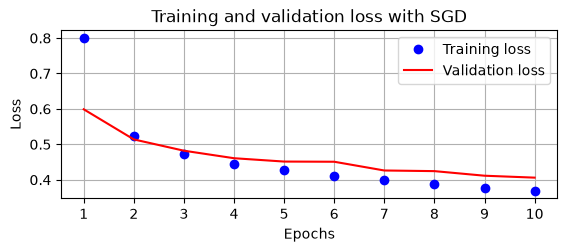

C:\Users\pomaa\AppData\Local\Temp\ipykernel_40836\3997593185.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \


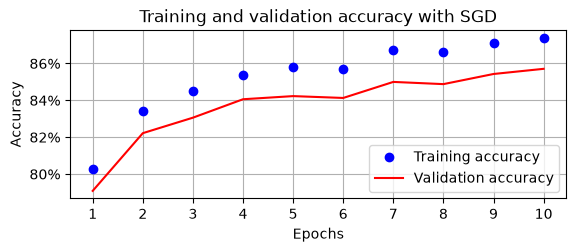

In [14]:
epoch = np.arange(10)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss with SGD')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy with SGD')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) \
                           for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()

 ### When learning rate is 0.1 (Higher Learning Rate)

In [ ]:

def get_model():
    model = nn.Sequential(
        nn.Linear(28*28, 1000),
        nn.ReLU(),
        nn.Linear(1000, 10)
    ).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=0.1)
    return model, loss, optimizer

In [16]:

tr_dataloader = getdata(tr_images, tr_targets, 32)
val_dataloader = getdata(val_images, val_targets, len(val_images))

model, loss, optimizer = get_model()

In [17]:
# model training and evalution
tr_losses, tr_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(10):
    print(epoch)
    epoch_losses, epoch_accuracies = [], []
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        batch_loss = train_model(model, x, y, loss, optimizer)
        epoch_losses.append(batch_loss)
    epoch_loss = np.array(epoch_losses).mean()
    print(f"Epoch {epoch}: loss = {epoch_loss}")
    
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        is_correct = accuracy(model, x, y)
        epoch_accuracies.extend(is_correct)
    epoch_accuracy = np.mean(epoch_accuracies)
    print(f"Epoch {epoch}: accuracy = {epoch_accuracy}")
    
    for ix, batch in enumerate(iter(val_dataloader)):
        x, y = batch
        val_is_correct = accuracy(model, x, y)
        validation_loss = val_loss(x, y, model, loss)
    val_epoch_accuracy = np.mean(val_is_correct)
    print(f"validation Loss: {validation_loss}")
    
    tr_losses.append(epoch_loss)
    tr_accuracies.append(epoch_accuracy)
    val_losses.append(validation_loss)
    val_accuracies.append(val_epoch_accuracy)
    
    
        

0
Epoch 0: loss = 2.487224755223592
Epoch 0: accuracy = 0.3337333333333333
validation Loss: 1.662476897239685
1
Epoch 1: loss = 2.0334322226524355
Epoch 1: accuracy = 0.20026666666666668
validation Loss: 2.077877998352051
2
Epoch 2: loss = 2.0742947576522828
Epoch 2: accuracy = 0.20831666666666668
validation Loss: 2.011951446533203
3
Epoch 3: loss = 2.0649797328948973
Epoch 3: accuracy = 0.19868333333333332
validation Loss: 2.0778214931488037
4
Epoch 4: loss = 2.081117667198181
Epoch 4: accuracy = 0.208
validation Loss: 2.0280039310455322
5
Epoch 5: loss = 2.040502972793579
Epoch 5: accuracy = 0.2005
validation Loss: 2.0315020084381104
6
Epoch 6: loss = 2.0406708943684895
Epoch 6: accuracy = 0.20346666666666666
validation Loss: 2.0347580909729004
7
Epoch 7: loss = 2.005969062487284
Epoch 7: accuracy = 0.22228333333333333
validation Loss: 2.0875298976898193
8
Epoch 8: loss = 2.0216525641123453
Epoch 8: accuracy = 0.2246
validation Loss: 2.057826280593872
9
Epoch 9: loss = 2.047165592257

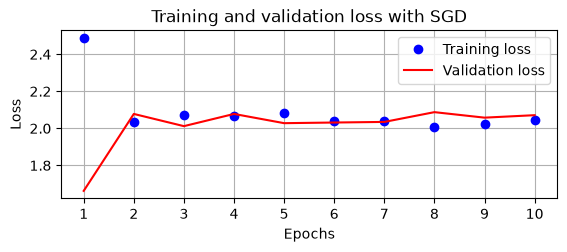

C:\Users\pomaa\AppData\Local\Temp\ipykernel_40836\786104081.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()])


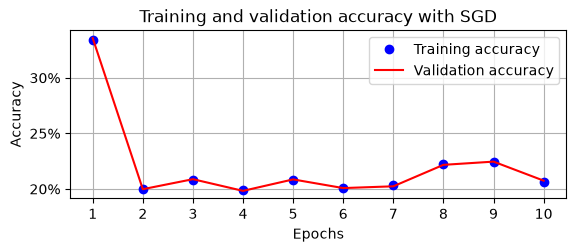

In [18]:
epoch = np.arange(10)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss with SGD')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy with SGD')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()

 ### When learning rate is 0.001 (Medium Learning Rate)

In [20]:
def get_model():
    model = nn.Sequential(
        nn.Linear(28*28, 1000),
        nn.ReLU(),
        nn.Linear(1000, 10)
    ).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=0.001)
    return model, loss, optimizer

In [21]:

tr_dataloader = getdata(tr_images, tr_targets, 32)
val_dataloader = getdata(val_images, val_targets, len(val_images))

model, loss, optimizer = get_model()

In [ ]:
# model training and evalution
tr_losses, tr_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(10):
    print(epoch)
    epoch_losses, epoch_accuracies = [], []
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        batch_loss = train_model(model, x, y, loss, optimizer)
        epoch_losses.append(batch_loss)
    epoch_loss = np.array(epoch_losses).mean()
    print(f"Epoch {epoch}: loss = {epoch_loss}")
    
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        is_correct = accuracy(model, x, y)
        epoch_accuracies.extend(is_correct)
    epoch_accuracy = np.mean(epoch_accuracies)
    print(f"Epoch {epoch}: accuracy = {epoch_accuracy}")
    
    for ix, batch in enumerate(iter(val_dataloader)):
        x, y = batch
        val_is_correct = accuracy(model, x, y)
        validation_loss = val_loss(x, y, model, loss)
    val_epoch_accuracy = np.mean(val_is_correct)
    print(f"validation Loss: {validation_loss}")
    
    tr_losses.append(epoch_loss)
    tr_accuracies.append(epoch_accuracy)
    val_losses.append(validation_loss)
    val_accuracies.append(val_epoch_accuracy)
    
    
        

0
Epoch 0: loss = 0.4717283174991608
Epoch 0: accuracy = 0.8757833333333334
validation Loss: 0.390781044960022
1
Epoch 1: loss = 0.3585348624606927
Epoch 1: accuracy = 0.8850166666666667
validation Loss: 0.3725191056728363
2
Epoch 2: loss = 0.31958736818830175
Epoch 2: accuracy = 0.88735
validation Loss: 0.3781912326812744
3
Epoch 3: loss = 0.29527412324349084
Epoch 3: accuracy = 0.8980333333333334
validation Loss: 0.3456931412220001
4
Epoch 4: loss = 0.27936691961884497
Epoch 4: accuracy = 0.9005666666666666
validation Loss: 0.34288713335990906
5
Epoch 5: loss = 0.2649501499543587
Epoch 5: accuracy = 0.9113166666666667
validation Loss: 0.3386130928993225
6
Epoch 6: loss = 0.25197001311083633
Epoch 6: accuracy = 0.9146333333333333
validation Loss: 0.3261094093322754
7
Epoch 7: loss = 0.23983430806969602
Epoch 7: accuracy = 0.9094
validation Loss: 0.3560875654220581
8
Epoch 8: loss = 0.22897065360546112
Epoch 8: accuracy = 0.9204666666666667
validation Loss: 0.34848421812057495
9
Epoch 

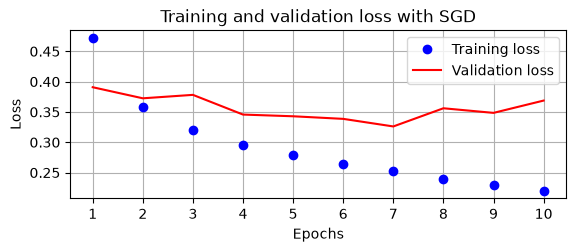

C:\Users\pomaa\AppData\Local\Temp\ipykernel_40836\786104081.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()])


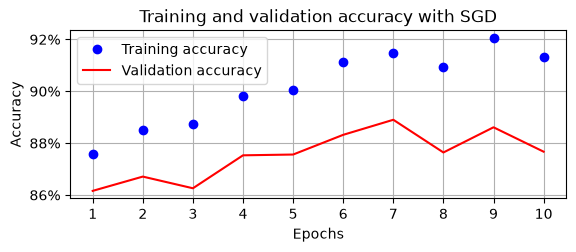

In [23]:
epoch = np.arange(10)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss with SGD')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy with SGD')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()

 ### When learning rate is 0.00001 (Low Learning Rate)

In [24]:
def get_model():
    model = nn.Sequential(
        nn.Linear(28*28, 1000),
        nn.ReLU(),
        nn.Linear(1000, 10)
    ).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=0.00001)
    return model, loss, optimizer

In [30]:

tr_dataloader = getdata(tr_images, tr_targets, 32)
val_dataloader = getdata(val_images, val_targets, len(val_images))

model, loss, optimizer = get_model()

In [26]:
# model training and evalution
tr_losses, tr_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(10):
    print(epoch)
    epoch_losses, epoch_accuracies = [], []
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        batch_loss = train_model(model, x, y, loss, optimizer)
        epoch_losses.append(batch_loss)
    epoch_loss = np.array(epoch_losses).mean()
    print(f"Epoch {epoch}: loss = {epoch_loss}")
    
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        is_correct = accuracy(model, x, y)
        epoch_accuracies.extend(is_correct)
    epoch_accuracy = np.mean(epoch_accuracies)
    print(f"Epoch {epoch}: accuracy = {epoch_accuracy}")
    
    for ix, batch in enumerate(iter(val_dataloader)):
        x, y = batch
        val_is_correct = accuracy(model, x, y)
        validation_loss = val_loss(x, y, model, loss)
    val_epoch_accuracy = np.mean(val_is_correct)
    print(f"validation Loss: {validation_loss}")
    
    tr_losses.append(epoch_loss)
    tr_accuracies.append(epoch_accuracy)
    val_losses.append(validation_loss)
    val_accuracies.append(val_epoch_accuracy)
    

0
Epoch 0: loss = 1.1427311473051707
Epoch 0: accuracy = 0.7558833333333334
validation Loss: 0.7703022956848145
1
Epoch 1: loss = 0.6723270980199179
Epoch 1: accuracy = 0.8009
validation Loss: 0.6326748728752136
2
Epoch 2: loss = 0.5795605042060217
Epoch 2: accuracy = 0.8192
validation Loss: 0.5729009509086609
3
Epoch 3: loss = 0.5322307887713115
Epoch 3: accuracy = 0.82925
validation Loss: 0.5387097001075745
4
Epoch 4: loss = 0.5020960187355678
Epoch 4: accuracy = 0.83435
validation Loss: 0.5174991488456726
5
Epoch 5: loss = 0.48056615703900657
Epoch 5: accuracy = 0.8408166666666667
validation Loss: 0.49927929043769836
6
Epoch 6: loss = 0.4640588744322459
Epoch 6: accuracy = 0.8424666666666667
validation Loss: 0.4870366156101227
7
Epoch 7: loss = 0.4511841092348099
Epoch 7: accuracy = 0.8490833333333333
validation Loss: 0.4752964973449707
8
Epoch 8: loss = 0.44011201725006105
Epoch 8: accuracy = 0.8531833333333333
validation Loss: 0.4645894169807434
9
Epoch 9: loss = 0.430900963242848

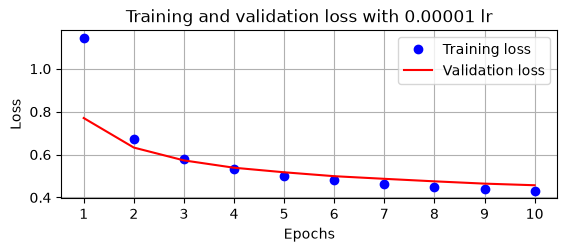

C:\Users\pomaa\AppData\Local\Temp\ipykernel_40836\4187173243.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()])


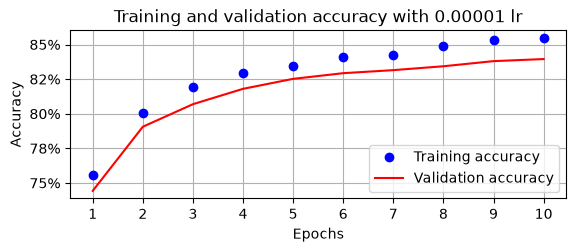

In [28]:
epoch = np.arange(10)+1
plt.subplot(211)
plt.plot(epoch, tr_losses, 'bo', label='Training loss')
plt.plot(epoch, val_losses, 'r', label='Validation loss')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation loss with 0.00001 lr')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid('off')
plt.show()
plt.subplot(212)
plt.plot(epoch, tr_accuracies, 'bo',label='Training accuracy')
plt.plot(epoch, val_accuracies, 'r', label='Validation accuracy')
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title('Training and validation accuracy with 0.00001 lr')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.gca().set_yticklabels(['{:.0f}%'.format(x*100) for x in plt.gca().get_yticks()]) 
plt.legend()
plt.grid('off')
plt.show()

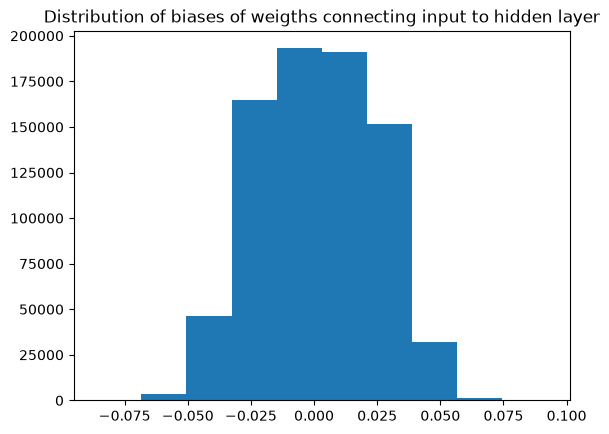

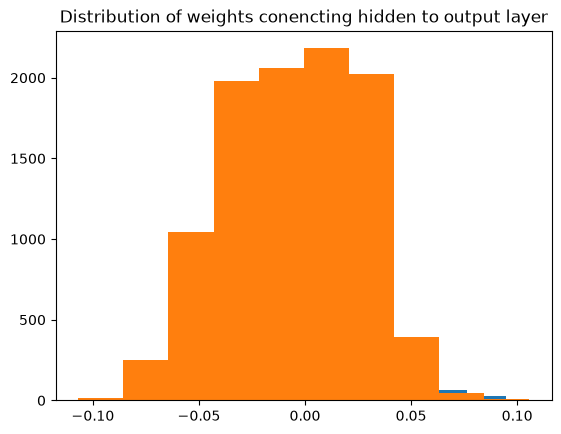

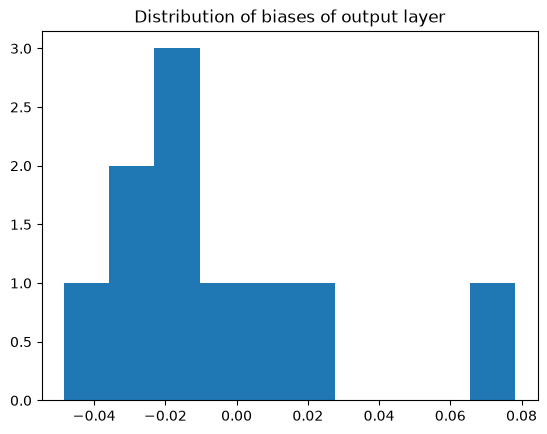

In [29]:
for ix, par in enumerate(model.parameters()):
    if ix==0:
        plt.hist(par.cpu().detach().numpy().flatten())
        plt.title('Distribution of biases of weigths connecting input to hidden layer')
        plt.show()
        
    elif ix == 1:
        plt.hist(par.cpu().detach().numpy().flatten())
        plt.title('Distribution of biases of hidden layer')
    elif(ix==2):
        plt.hist(par.cpu().detach().numpy().flatten())
        plt.title('Distribution of weights conencting hidden to output layer')
        plt.show()
    elif(ix ==3):
        plt.hist(par.cpu().detach().numpy().flatten())
        plt.title('Distribution of biases of output layer')
        plt.show()
        

### Using a learning rate scheduler

In [31]:
from torch import optim

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=0, threshold=0.001, verbose=True, min_lr=0.00001, threshold_mode='abs')

c:\Users\pomaa\miniconda3\envs\cv2\Lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [32]:
# model training and evalution
tr_losses, tr_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(10):
    print(epoch)
    epoch_losses, epoch_accuracies = [], []
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        batch_loss = train_model(model, x, y, loss, optimizer)
        epoch_losses.append(batch_loss)
    epoch_loss = np.array(epoch_losses).mean()
    print(f"Epoch {epoch}: loss = {epoch_loss}")
    
    for ix, batch in enumerate(iter(tr_dataloader)):
        x, y = batch
        is_correct = accuracy(model, x, y)
        epoch_accuracies.extend(is_correct)
    epoch_accuracy = np.mean(epoch_accuracies)
    print(f"Epoch {epoch}: accuracy = {epoch_accuracy}")
    
    for ix, batch in enumerate(iter(val_dataloader)):
        x, y = batch
        val_is_correct = accuracy(model, x, y)
        validation_loss = val_loss(x, y, model, loss)
        scheduler.step(validation_loss)
    val_epoch_accuracy = np.mean(val_is_correct)
    print(f"validation Loss: {validation_loss}")
    
    tr_losses.append(epoch_loss)
    tr_accuracies.append(epoch_accuracy)
    val_losses.append(validation_loss)
    val_accuracies.append(val_epoch_accuracy)
    

0
Epoch 0: loss = 1.1495266568024953
Epoch 0: accuracy = 0.7564333333333333
validation Loss: 0.7712815403938293
1
Epoch 1: loss = 0.673007193549474
Epoch 1: accuracy = 0.8022333333333334
validation Loss: 0.6361825466156006
2
Epoch 2: loss = 0.5809226980686187
Epoch 2: accuracy = 0.8171666666666667
validation Loss: 0.5758444666862488
3
Epoch 3: loss = 0.5341013549804687
Epoch 3: accuracy = 0.8282166666666667
validation Loss: 0.5415470600128174
4
Epoch 4: loss = 0.504154449558258
Epoch 4: accuracy = 0.8351333333333333
validation Loss: 0.5174466967582703
5
Epoch 5: loss = 0.48278467381000517
Epoch 5: accuracy = 0.8407166666666667
validation Loss: 0.5020605325698853
6
Epoch 6: loss = 0.46668279736042023
Epoch 6: accuracy = 0.8450666666666666
validation Loss: 0.4875101149082184
7
Epoch 7: loss = 0.4534649224440257
Epoch 7: accuracy = 0.8466166666666667
validation Loss: 0.47945675253868103
8
Epoch 8: loss = 0.4429621127049128
Epoch 8: accuracy = 0.8512833333333333
validation Loss: 0.46976327